Choose an image dataset.
1. Produce a montage that reveals something about the data, plus one structural visualization (channels/intensity).
2. If feasible, add a saliency or feature-map view for one example and interpret it.
3. Submit as a Streamlit app (image browser).

Optional Extensions (Challenge yourself)
1. Add a class-balance bar chart alongside the montage.
2. Let the Streamlit app overlay a saliency heatmap on the uploaded image.
3. Compare two classes’ intensity distributions.

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits

In [8]:
from pathlib import Path
from PIL import Image
import numpy as np
import pandas as pd

root = Path("data")
classes = sorted(d.name for d in root.iterdir() if d.is_dir() and d.name != "data")

images, labels = [], []
for cls in classes:
    for p in sorted((root / cls).iterdir()):
        if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp"}:
            images.append(np.array(Image.open(p).convert("RGB").resize((128, 128))))
            labels.append(cls)

images = np.stack(images)
labels = np.array(labels)
print(images.shape)                       
print(pd.Series(labels).value_counts())   

(1803, 128, 128, 3)
cars       420
bike       365
flowers    210
cats       202
dogs       202
horses     202
human      202
Name: count, dtype: int64


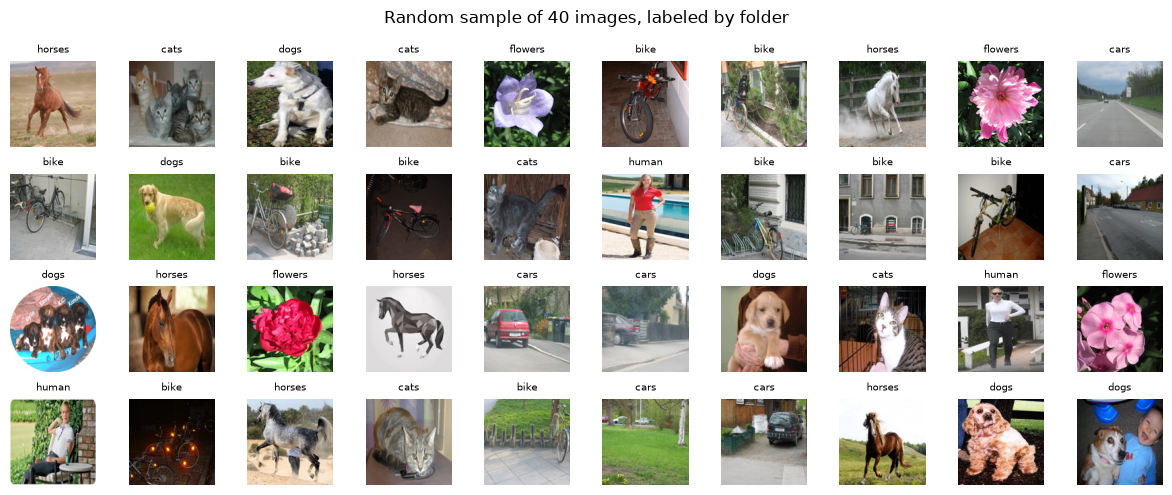

In [10]:
idx = np.random.default_rng(0).choice(len(images), 40, replace=False)
fig, axes = plt.subplots(4, 10, figsize=(12, 5))
for ax, i in zip(axes.ravel(), idx):
    ax.imshow(images[i]); ax.set_title(labels[i], fontsize=7); ax.axis("off")
plt.suptitle("Random sample of 40 images, labeled by folder")
plt.tight_layout(); plt.show()


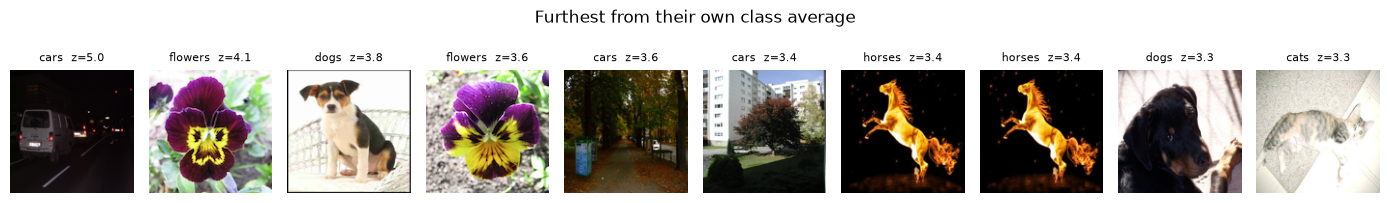

In [11]:
imgs = images.astype(float) 

means = {k: imgs[labels == k].mean(axis=0) for k in classes}
dist = np.array([np.linalg.norm(imgs[i] - means[labels[i]])
                 for i in range(len(labels))])
z = np.zeros_like(dist)
for k in classes:
    m = labels == k
    z[m] = (dist[m] - dist[m].mean()) / dist[m].std()

odd = np.argsort(-z)[:10]
fig, axes = plt.subplots(1, 10, figsize=(14, 2.2))
for ax, i_ in zip(axes, odd):
    ax.imshow(images[i_])
    ax.set_title(f"{labels[i_]}  z={z[i_]:.1f}", fontsize=8); ax.axis("off")
plt.suptitle("Furthest from their own class average")
plt.tight_layout(); plt.show()


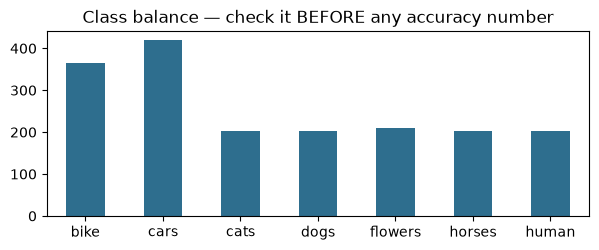

In [13]:
import pandas as pd
pd.Series(labels).value_counts().sort_index().plot.bar(
    figsize=(7, 2.4), color="#2E6E8E", rot=0, title="Class balance — check it BEFORE any accuracy number")
plt.show()

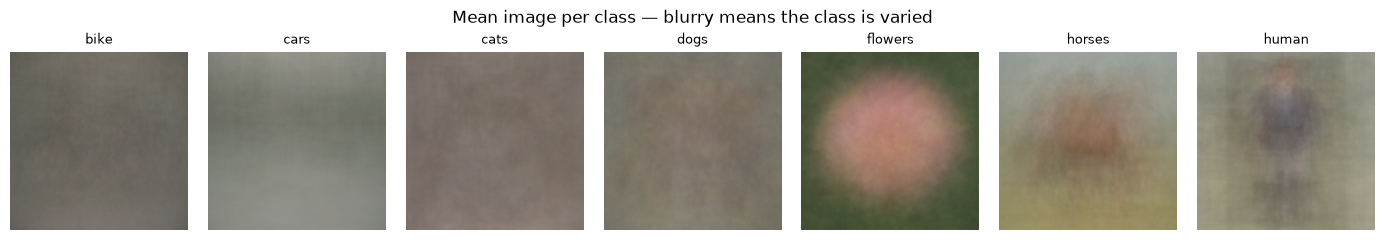

In [15]:
fig, axes = plt.subplots(1, len(classes), figsize=(14, 2.4))
for cls, ax in zip(classes, axes):
    ax.imshow(images[labels == cls].mean(axis=0) / 255)
    ax.set_title(cls, fontsize=9); ax.axis("off")
plt.suptitle("Mean image per class — blurry means the class is varied")
plt.tight_layout(); plt.show()

In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix

M = np.array([images[labels == k].mean(axis=0).ravel() for k in classes])
D = np.linalg.norm(M[:, None] - M[None, :], axis=2); np.fill_diagonal(D, np.inf)

X = images[:, ::4, ::4].reshape(len(images), -1) / 255   # 32x32x3, scaled to 0-1
pred = cross_val_predict(LogisticRegression(max_iter=2000), X, labels, cv=5)
cm = confusion_matrix(labels, pred, labels=classes)

rows = [{"pair": f"{classes[i_]} vs {classes[j]}", "mean distance": round(D[i_, j], 1),
         "times confused": int(cm[i_, j] + cm[j, i_])}
        for i_ in range(len(classes)) for j in range(i_ + 1, len(classes))]
df = pd.DataFrame(rows)

print("Accuracy: %.2f" % (pred == labels).mean())
print("\nCLOSEST MEANS:"); print(df.nsmallest(5, "mean distance").to_string(index=False))
print("\nMOST CONFUSED:"); print(df.nlargest(5, "times confused").to_string(index=False))
print("\nSpearman correlation: %.2f" %
      df["mean distance"].corr(df["times confused"], method="spearman"))

Accuracy: 0.44

CLOSEST MEANS:
        pair  mean distance  times confused
cats vs dogs         1239.7              56
bike vs cats         2930.7             121
bike vs dogs         3080.5              85
cars vs dogs         3535.1              69
cars vs cats         3547.7              72

MOST CONFUSED:
        pair  mean distance  times confused
bike vs cars         5690.1             218
bike vs cats         2930.7             121
bike vs dogs         3080.5              85
cars vs cats         3547.7              72
cars vs dogs         3535.1              69

Spearman correlation: -0.77


cats: mean 113.7 | 0.1% black | 2.3% near-saturated
dogs: mean 114.3 | 0.1% black | 1.7% near-saturated


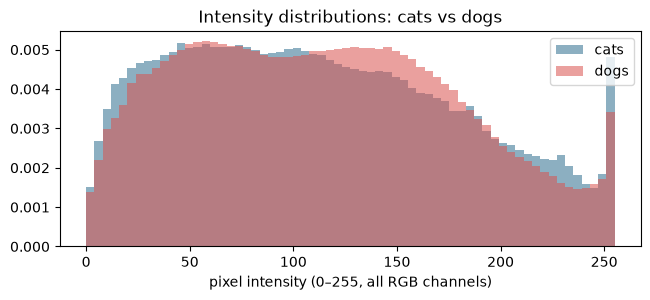

In [20]:
pair = ["cats", "dogs"]
fig, ax = plt.subplots(figsize=(7.5, 2.8))
for cls, color in zip(pair, ["#2E6E8E", "#d9534f"]):
    vals = images[labels == cls].ravel()
    ax.hist(vals, bins=64, range=(0, 255), alpha=0.55, density=True, label=cls, color=color)
    print(f"{cls}: mean {vals.mean():.1f} | {np.mean(vals == 0):.1%} black "
          f"| {np.mean(vals >= 250):.1%} near-saturated")
ax.legend(); ax.set_xlabel("pixel intensity (0–255, all RGB channels)")
ax.set_title(f"Intensity distributions: {pair[0]} vs {pair[1]}")
plt.show()

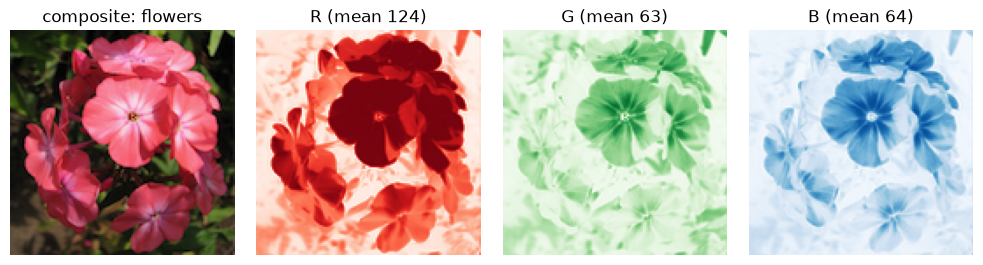

In [38]:
cls = "flowers"
img = images[np.where(labels == cls)[0][0]]

fig, axes = plt.subplots(1, 4, figsize=(10, 2.6))
axes[0].imshow(img); axes[0].set_title(f"composite: {cls}")
for k, (n, cm) in enumerate([("R", "Reds"), ("G", "Greens"), ("B", "Blues")]):
    axes[k+1].imshow(img[..., k], cmap=cm, vmin=0, vmax=255)
    axes[k+1].set_title(f"{n} (mean {img[..., k].mean():.0f})")
for a in axes: a.axis("off")
plt.tight_layout(); plt.show()

numpy .shape : (4, 8)  (height, width)
PIL   .size  : (8, 4)  (width, height)  <- reversed


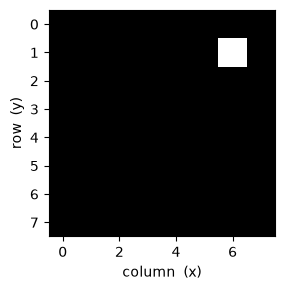

imshow extent (left, right, bottom, top): [-0.5, 7.5, 7.5, -0.5]


In [39]:
from PIL import Image

a = np.zeros((4, 8), dtype=np.uint8)
print("numpy .shape :", a.shape, " (height, width)")
print("PIL   .size  :", Image.fromarray(a).size, " (width, height)  <- reversed")

b = np.zeros((8, 8)); b[1, 6] = 1
fig, ax = plt.subplots(figsize=(3, 3))
ax.imshow(b, cmap="gray"); ax.set_xlabel("column  (x)"); ax.set_ylabel("row  (y)")
plt.tight_layout(); plt.show()

# Ask the room where b[1, 6] will light up BEFORE running this cell.
print("imshow extent (left, right, bottom, top):", ax.images[0].get_extent())

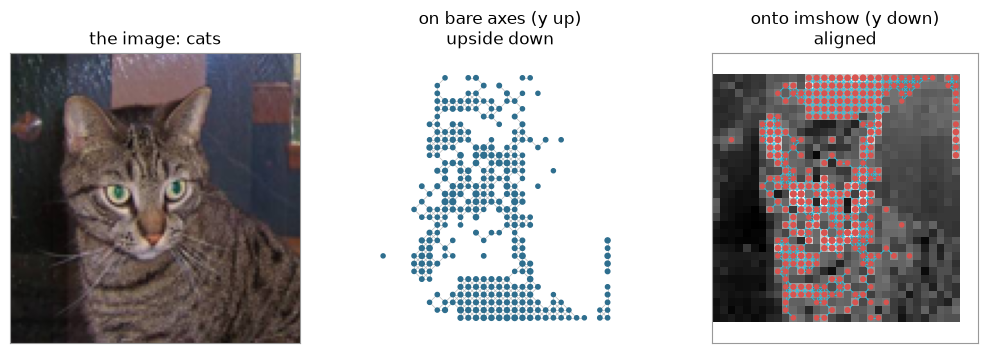

304 nodes, 744 edges (node size = pixel brightness, threshold = 87)
4-connectivity:  382 edges
8-connectivity:  744 edges
connected regions: 10


In [40]:
import networkx as nx

NBR8 = [(-1,0),(1,0),(0,-1),(0,1),(-1,-1),(-1,1),(1,-1),(1,1)]

def pixel_graph(img, thresh, neighbors=NBR8):
    """Nodes are pixels brighter than thresh; edges join neighboring pixels."""
    G = nx.Graph()
    for i in range(img.shape[0]):
        for j in range(img.shape[1]):
            if img[i, j] > thresh:
                G.add_node((i, j))
    for (i, j) in list(G.nodes):
        for di, dj in neighbors:
            if (i + di, j + dj) in G:
                G.add_edge((i, j), (i + di, j + dj))
    return G


cls = "cats"
color_img = images[np.where(labels == cls)[0][0]]
img = color_img[::4, ::4].mean(axis=2)            # 32x32 grayscale, values 0-255
thresh = np.percentile(img, 70)                   # keep the brightest 30% of pixels
G = pixel_graph(img, thresh)
pos = {(i, j): (j, i) for (i, j) in G.nodes}
sizes = [img[i, j] / 255 * 25 for (i, j) in G.nodes]

fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.6))
axes[0].imshow(color_img); axes[0].set_title(f"the image: {cls}")
nx.draw(G, pos, ax=axes[1], node_size=sizes, node_color="#2E6E8E",
        edge_color="#bbbbbb", width=0.5)
axes[1].set_title("on bare axes (y up)\nupside down"); axes[1].set_aspect("equal")
axes[2].imshow(img, cmap="gray")
nx.draw_networkx_edges(G, pos, ax=axes[2], edge_color="#00d5ff", width=0.5)
nx.draw_networkx_nodes(G, pos, ax=axes[2], node_size=sizes, node_color="#d9534f")
axes[2].set_title("onto imshow (y down)\naligned")
for a_ in (axes[0], axes[2]):
    a_.set_xticks([]); a_.set_yticks([])
    for s_ in a_.spines.values(): s_.set_edgecolor("#999999")
plt.tight_layout(); plt.show()

print(f"{G.number_of_nodes()} nodes, {G.number_of_edges()} edges "
      f"(node size = pixel brightness, threshold = {thresh:.0f})")

G4 = pixel_graph(img, thresh, NBR8[:4])
print(f"4-connectivity: {G4.number_of_edges():4d} edges")
print(f"8-connectivity: {G.number_of_edges():4d} edges")
print(f"connected regions: {nx.number_connected_components(G)}")


test accuracy: 48.1%
map range: -0.0182 .. 0.0012


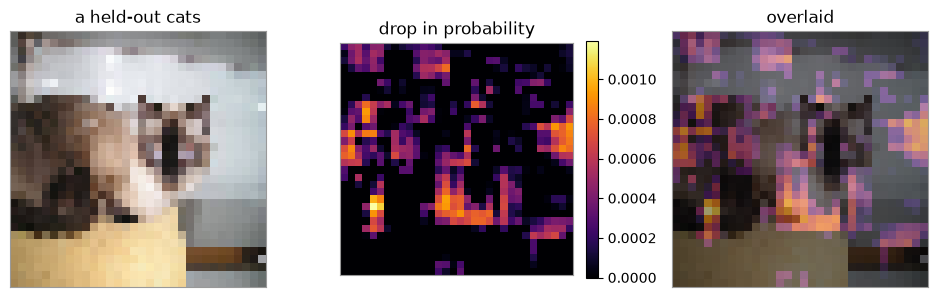

In [41]:
from sklearn.model_selection import train_test_split

small = images[:, ::4, ::4] / 255                  # (n, 32, 32, 3), values 0-1
Xtr, Xte, ytr, yte = train_test_split(small, labels, test_size=0.3,
                                      random_state=0, stratify=labels)
clf = LogisticRegression(max_iter=2000).fit(Xtr.reshape(len(Xtr), -1), ytr)
print("test accuracy: %.1f%%" % (100 * clf.score(Xte.reshape(len(Xte), -1), yte)))


def occlude(model, img, cls, patch=5):
    """Slide a mean-colored patch over the image; record how far P(cls) falls."""
    k = list(model.classes_).index(cls)
    h, w = img.shape[:2]
    r, fill = patch // 2, img.mean(axis=(0, 1))
    base = model.predict_proba([img.ravel()])[0][k]
    batch = []
    for i in range(h):
        for j in range(w):
            t = img.copy()
            t[max(0, i - r):i + r + 1, max(0, j - r):j + r + 1] = fill
            batch.append(t.ravel())
    return (base - model.predict_proba(np.array(batch))[:, k]).reshape(h, w)


def show_saliency(img, sal, title, mark=None):
    """Three panels: the image, the map, the overlay."""
    from matplotlib.patches import Rectangle
    fig, axes = plt.subplots(1, 3, figsize=(9.5, 3))
    axes[0].imshow(img); axes[0].set_title(title)
    # "hot" tops out at white, which disappears on a white page; "inferno" does not.
    hm = axes[1].imshow(sal, cmap="inferno", vmin=0)
    axes[1].set_title("drop in probability"); fig.colorbar(hm, ax=axes[1], fraction=0.046)
    axes[2].imshow(img)
    axes[2].imshow(sal, cmap="inferno", alpha=0.55, vmin=0)
    axes[2].set_title("overlaid")
    for a in axes:
        a.set_xticks([]); a.set_yticks([])
        for s in a.spines.values(): s.set_edgecolor("#999999")
        if mark is not None:
            a.add_patch(Rectangle((-0.5, -0.5), mark, mark, fill=False,
                                  edgecolor="#00d5ff", lw=2))
    plt.tight_layout(); plt.show()


cls = "cats"
img0 = Xte[np.where(yte == cls)[0][0]]
sal0 = occlude(clf, img0, cls)
print("map range: %.4f .. %.4f" % (sal0.min(), sal0.max()))
show_saliency(img0, sal0, f"a held-out {cls}")


In [42]:
k = list(clf.classes_).index(cls)
print("predicted:", clf.predict([img0.ravel()])[0], "| P(cats) = %.2f" % clf.predict_proba([img0.ravel()])[0][k])

predicted: horses | P(cats) = 0.00


using test image 58, P(cats) = 1.00


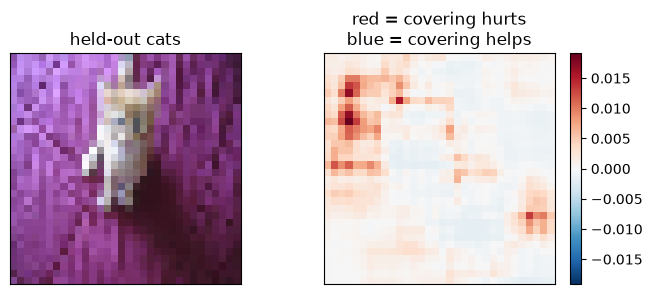

In [43]:
Xte_flat = Xte.reshape(len(Xte), -1)
probs = clf.predict_proba(Xte_flat)[:, list(clf.classes_).index(cls)]
right = np.where((yte == cls) & (clf.predict(Xte_flat) == cls))[0]
best = right[np.argmax(probs[right])]
print(f"using test image {best}, P({cls}) = {probs[best]:.2f}")

img0 = Xte[best]
sal0 = occlude(clf, img0, cls, patch=9)
lim = np.abs(sal0).max()

fig, axes = plt.subplots(1, 2, figsize=(7, 3))
axes[0].imshow(img0); axes[0].set_title(f"held-out {cls}")
hm = axes[1].imshow(sal0, cmap="RdBu_r", vmin=-lim, vmax=lim)
axes[1].set_title("red = covering hurts\nblue = covering helps")
fig.colorbar(hm, ax=axes[1], fraction=0.046)
for a in axes: a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

In [44]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline

Xtr_flat, Xte_flat = Xtr.reshape(len(Xtr), -1), Xte.reshape(len(Xte), -1)
models = {
    "logistic regression": clf,
    "random forest": RandomForestClassifier(n_estimators=300, random_state=0, n_jobs=-1),
    "SVM (PCA 100)": make_pipeline(PCA(100, random_state=0), SVC(probability=True, random_state=0)),
}
for name, m in models.items():
    if m is not clf:
        m.fit(Xtr_flat, ytr)
    print(f"{name:20s} test accuracy: {100 * m.score(Xte_flat, yte):.1f}%")


logistic regression  test accuracy: 48.1%
random forest        test accuracy: 58.4%


/Users/halaassaf/Desktop/Fall 2026/Data Viz/Class 8/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


SVM (PCA 100)        test accuracy: 60.4%
